## Predicted AirLine Satifaction

In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("../data/train.csv")
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [3]:
train.shape

(699635, 23)

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [5]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.00000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.37213,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.00000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.50000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.00000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.50000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.00000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


In [6]:
train.isnull().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

Correlation: 0.29127495749087207


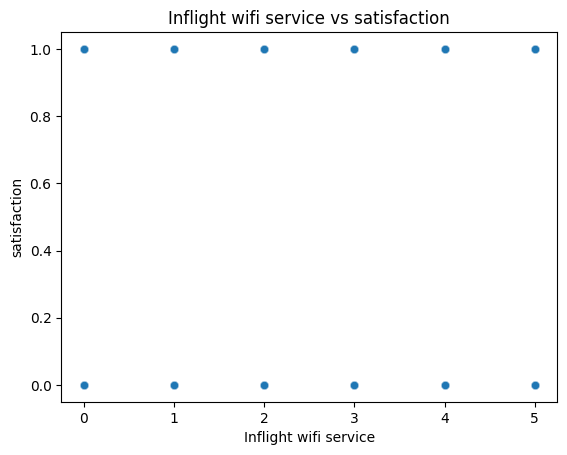

In [7]:
x_col = "Inflight wifi service"
y_col = "satisfaction"

print("Correlation:", train[x_col].corr(train[y_col]))

sns.scatterplot(data=train, x=x_col, y=y_col, alpha=0.3)
plt.title(f"{x_col} vs {y_col}")
plt.show()

In [8]:
train['Arrival Delay in Minutes'].fillna(train['Arrival Delay in Minutes'].mean(), inplace=True)

C:\Users\zeeshan\AppData\Local\Temp\ipykernel_1604\877323869.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Arrival Delay in Minutes'].fillna(train['Arrival Delay in Minutes'].mean(), inplace=True)


In [9]:
train['satisfaction'].value_counts(normalize=True)

satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

In [10]:
X = pd.get_dummies(train.drop(columns=['satisfaction']), drop_first=True)
y = train['satisfaction']

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

In [15]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

proba = model.predict_proba(X_val)[:, 1]

print("accuracy_score:", accuracy_score(y_val, y_pred))
print('rac auc score:', roc_auc_score(y_val, proba))



accuracy_score: 0.9240961358422606
rac auc score: 0.9540601352923309


In [16]:
sample = pd.read_csv("../data/sample_submission.csv")
sample.head()

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [18]:
test = pd.read_csv("../data/test.csv")

test["Arrival Delay in Minutes"] = test["Arrival Delay in Minutes"].fillna(
    train["Arrival Delay in Minutes"].mean()
)

test_X = pd.get_dummies(
    test.drop(columns=["satisfaction"], errors="ignore"),
    drop_first=True
).reindex(columns=X.columns, fill_value=0)

positive_class_index = list(model.classes_).index(True)
test_proba = model.predict_proba(test_X)[:, positive_class_index]

predictions = pd.DataFrame({
    "id": test["id"],
    "satisfaction": test_proba
})

submission = sample[["id"]].merge(
    predictions, on="id", how="left", validate="one_to_one"
)

submission.to_csv("submission.csv", index=False)

In [20]:
sample_submission = pd.read_csv('submission.csv')
sample_submission.head()

,id,satisfaction
0,699635,0.30
1,699636,0.92
2,699637,0.75
3,699638,0.25
4,699639,0.15


In [24]:
print(sample_submission.shape, sample_submission.shape)
# print(sample_submission["satisfaction"].isna().sum())   # should be 0
print(sample_submission["satisfaction"].describe())

(299844, 2) (299844, 2)
count    299844.000000
mean          0.447967
std           0.352573
min           0.000000
25%           0.110000
50%           0.290000
75%           0.830000
max           1.000000
Name: satisfaction, dtype: float64
